# Big Data Analytics — Maharashtra Kharif Crop Yields (2016–2025)

This notebook walks through the Spark data lake built by `python run_all.py`:
**~2 million farm-season records**, ~617k daily weather readings, ~210k nested-JSON Soil Health Card tests and 200k farms across 34 districts and 367 talukas.

| Layer | What it holds |
|---|---|
| Landing zone (`data/raw`) | messy CSV + JSON exactly as received |
| Bronze | raw data as Parquet with lineage columns |
| Silver | cleaned, typed, de-duplicated, unit-normalised, partitioned |
| Gold | one analytical row per farm-season: weather aggregates + soil + farm + geography |

*The data is simulated (`data_generator.py`) from agronomic response curves with realistic noise and data-quality problems.*

In [1]:
import json, os, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F
from bda.config import BRONZE, SILVER, GOLD, OUTPUTS, MODEL_OUT, STREAM_OUT, get_spark, p

spark = get_spark("notebook")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})

Spark 3.5.9 | cores: 2


## 1. The data lake and what ingestion fixed

In [2]:
def mb(path): return sum(f.stat().st_size for f in Path(path).rglob('*') if f.is_file()) / 1e6
sizes = {layer: round(mb(Path('data') / sub), 1) for layer, sub in
         [('raw (CSV + JSON)', 'raw'), ('bronze (Parquet)', 'lake/bronze'), ('silver (Parquet)', 'lake/silver'), ('gold (Parquet)', 'lake/gold')]}
display(pd.Series(sizes, name='MB').to_frame())
display(pd.Series(json.load(open(OUTPUTS / 'quality_report.json')), name='count').to_frame())

,MB
raw (CSV + JSON),208.3
bronze (Parquet),41.8
silver (Parquet),35.1
gold (Parquet),65.0


,count
farm_seasons_raw_rows,2006000.0
exact_duplicate_records,6000.0
crop_name_variants_fixed,120788.0
dates_in_dd_mm_yyyy,301155.0
yields_reported_in_quintals,188444.0
nitrogen_missing,59941.0
nitrogen_implausible_set_null,988.0
variety_missing,20045.0
farm_seasons_silver_rows,1999002.0
implausible_yield_rows_removed,998.0


Nested JSON (Variety): the Soil Health Card `results` field is a struct that Spark reads without flattening first.

In [3]:
soil = spark.read.parquet(p(BRONZE / 'soil_health_cards'))
soil.printSchema()
soil.select('farm_id', 'cycle', 'sample_date', 'results.pH', 'results.OC_pct').show(5)

root
 |-- card_id: string (nullable = true)
 |-- cycle: long (nullable = true)
 |-- farm_id: string (nullable = true)
 |-- lab: string (nullable = true)
 |-- results: struct (nullable = true)
 |    |-- EC_dS_m: double (nullable = true)
 |    |-- K_kg_ha: long (nullable = true)
 |    |-- N_kg_ha: long (nullable = true)
 |    |-- OC_pct: double (nullable = true)
 |    |-- P_kg_ha: double (nullable = true)
 |    |-- pH: double (nullable = true)
 |-- sample_date: string (nullable = true)
 |-- _source_file: string (nullable = true)
 |-- _ingested_at: timestamp (nullable = true)



+-------+-----+-----------+---+------+
|farm_id|cycle|sample_date| pH|OC_pct|
+-------+-----+-----------+---+------+
|F000002|    1| 2015-09-05|7.3|  0.47|
|F000002|    2| 2017-12-09|7.3|  0.54|
|F000003|    1| 2016-09-30|6.8|  0.58|
|F000006|    1| 2015-09-30|5.5|   1.1|
|F000007|    1| 2016-05-30|5.1|  0.76|
+-------+-----+-----------+---+------+
only showing top 5 rows



Hive-style partitioning: each season is its own folder, so queries that filter on `season_year` skip the rest.

In [4]:
print(sorted(x.name for x in (SILVER / 'farm_seasons').iterdir() if x.is_dir()))
gold = spark.read.parquet(p(GOLD / 'farm_season_features'))
print(f"Gold rows: {gold.count():,} | columns: {len(gold.columns)}")
gold.filter('season_year = 2024').groupBy('crop').count().explain()

['season_year=2016', 'season_year=2017', 'season_year=2018', 'season_year=2019', 'season_year=2020', 'season_year=2021', 'season_year=2022', 'season_year=2023', 'season_year=2024', 'season_year=2025']


Gold rows: 1,999,002 | columns: 30


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[crop#56], functions=[count(1)])
   +- Exchange hashpartitioning(crop#56, 16), ENSURE_REQUIREMENTS, [plan_id=72]
      +- HashAggregate(keys=[crop#56], functions=[partial_count(1)])
         +- Project [crop#56]
            +- FileScan parquet [crop#56,season_year#82] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/home/claude/proj3/MiniProj/data/lake/gold/farm_season_features], PartitionFilters: [isnotnull(season_year#82), (season_year#82 = 2024)], PushedFilters: [], ReadSchema: struct<crop:string>




## 2. Window functions on the weather table
For one weather station and season, Spark finds the **monsoon onset** (first day whose 3-day rainfall reaches 40 mm) and the **longest dry spell** using the gaps-and-islands technique.

In [5]:
from bda.features import season_weather
sw = spark.read.parquet(p(GOLD / 'season_weather'))
display(sw.filter("station_id = 'YTL-WS01'").orderBy('year').toPandas()[
    ['year', 'onset_date', 'season_rain_mm', 'rainy_days', 'longest_dry_spell_days', 'mean_temp_c']].round(1))

,year,onset_date,season_rain_mm,rainy_days,longest_dry_spell_days,mean_temp_c
0,2016,2016-06-14,658.1,41,20,27.3
1,2017,2017-06-18,810.1,44,10,28.2
2,2018,2018-06-12,1053.8,51,6,27.3
3,2019,2019-06-27,830.0,43,12,28.2
4,2020,2020-06-16,962.8,54,8,27.3
5,2021,2021-06-29,814.2,43,12,28.3
6,2022,2022-06-14,1050.6,54,13,28.5
7,2023,2023-07-09,730.2,31,12,28.3
8,2024,2024-06-25,623.0,42,10,26.7
9,2025,2025-06-15,933.6,41,22,27.7


## 3. Spark SQL analytics

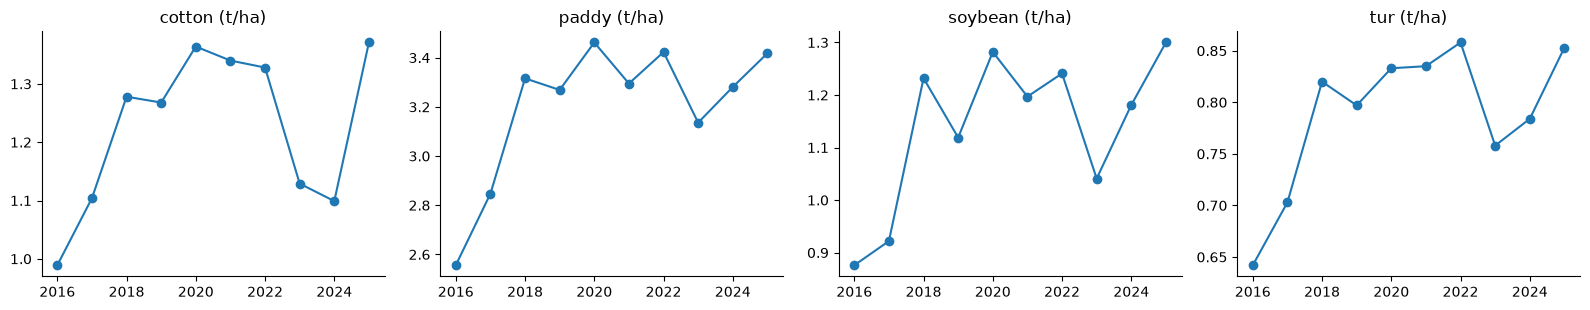

In [6]:
gold.createOrReplaceTempView('gold')
trend = spark.sql('''
  SELECT crop, season_year, ROUND(AVG(yield_t_ha), 3) AS mean_yield, COUNT(*) AS farms
  FROM gold GROUP BY crop, season_year ORDER BY crop, season_year''').toPandas()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (crop, g) in zip(axes, trend.groupby('crop')):
    ax.plot(g.season_year, g.mean_yield, marker='o'); ax.set_title(f'{crop} (t/ha)')
plt.tight_layout(); plt.show()

In [7]:
impact = spark.sql('''
  SELECT crop, rain_category, irrigated, ROUND(AVG(yield_t_ha), 3) AS mean_yield, COUNT(*) AS n
  FROM gold GROUP BY 1, 2, 3''').toPandas()
display(impact.pivot_table(index=['crop', 'irrigated'], columns='rain_category', values='mean_yield')[['deficient', 'normal', 'excess']])

rain_category      deficient  normal  excess
crop    irrigated                           
cotton  0              0.750   1.179   1.365
        1              1.282   1.411   1.419
paddy   0              2.365   3.149   3.448
        1              2.651   3.425   3.777
soybean 0              0.582   1.016   1.272
        1              1.238   1.398   1.449
tur     0              0.505   0.745   0.848
        1              0.832   0.895   0.892

Irrigation acts like insurance: rain-fed yields fall sharply in deficient seasons, while irrigated yields barely move.

### Anomaly detection
District-crop-seasons far below their own history. When rainfall was normal, the cause is probably not weather. Because the data is simulated, the planted pest outbreaks are known, so we can check how well this simple rule finds them.

In [8]:
an = pd.read_csv(OUTPUTS / 'analytics' / 'yield_anomalies.csv')
truth = pd.read_csv('data/truth/pest_outbreaks.csv')
m = an.merge(truth, on=['season_year', 'district_code', 'crop'], how='left')
display(pd.crosstab(m.likely_cause, m.loss_share.notna().rename('real outbreak')))
nonw = m[m.likely_cause.str.startswith('non-weather')]
print(f"precision of 'non-weather' flags: {nonw.loss_share.notna().mean():.0%} | "
      f"recall: {m.loss_share.notna().sum()} of {len(truth[truth.season_year < 2026])} planted outbreaks found")

real outbreak,False,True
likely_cause,,
drought (rain deficit),21,3
non-weather: pest or disease suspected,11,15


precision of 'non-weather' flags: 58% | recall: 18 of 50 planted outbreaks found


## 4. Spark MLlib results (train 2016–2023, test 2024–2025)

,linear R2,GBT R2,GBT MAE,R2 ceiling
crop,,,,
overall,0.7214,0.9150,0.2325,0.948
paddy,0.5626,0.8664,0.4635,0.923
soybean,0.0588,0.7092,0.1911,0.837
cotton,-0.0721,0.5331,0.2066,0.622
tur,-2.1070,0.6569,0.1105,0.806


best tuning params: {'maxDepth': 7, 'maxIter': 80, 'stepSize': 0.1, 'val_rmse': 0.3427}


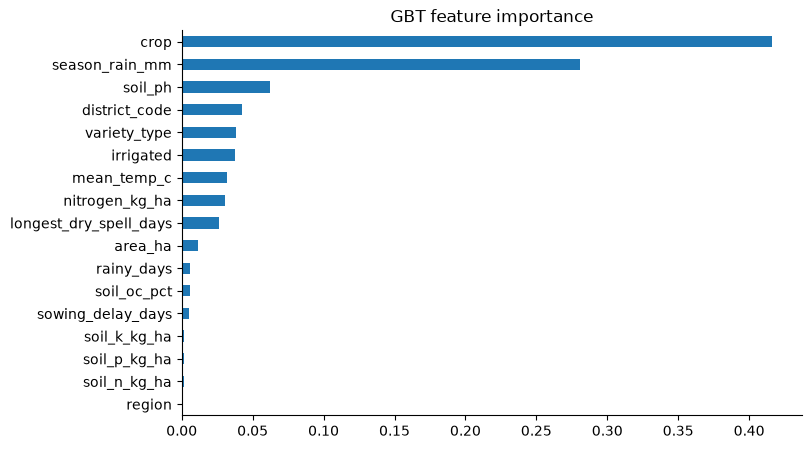

In [9]:
mt = json.load(open(MODEL_OUT / 'metrics.json'))
ceil = json.load(open('data/truth/ceiling.json'))['r2_ceiling_test_years']
rows = [(c, mt['linear_regression'][c]['r2'], mt['gbt'][c]['r2'], mt['gbt'][c]['mae'], ceil['all_crops' if c == 'overall' else c])
        for c in ['overall', 'paddy', 'soybean', 'cotton', 'tur']]
res = pd.DataFrame(rows, columns=['crop', 'linear R2', 'GBT R2', 'GBT MAE', 'R2 ceiling']).set_index('crop')
display(res); print('best tuning params:', mt['best_params'])
pd.Series(mt['feature_importance']).sort_values().plot.barh(figsize=(8, 5), title='GBT feature importance'); plt.show()

**Read the overall R² with care.** Most of it comes from learning that paddy yields more than tur. The per-crop rows are the honest measure, and they should be compared with the *ceiling*: the best R² any model could reach given the unobservable noise, which is known here because the data is simulated.

In [10]:
from pyspark.ml import PipelineModel
model = PipelineModel.load(p(MODEL_OUT / 'gbt_pipeline'))
sample = gold.filter('season_year = 2025').limit(8)
model.transform(sample).select('district', 'crop', 'irrigated', F.round('season_rain_mm').alias('season_rain_mm'), 'yield_t_ha',
                               F.round('prediction', 2).alias('predicted')).show()

+--------+-------+---------+--------------+----------+---------+
|district|   crop|irrigated|season_rain_mm|yield_t_ha|predicted|
+--------+-------+---------+--------------+----------+---------+
|  Nagpur|soybean|        1|        1286.0|     1.294|      1.5|
|  Nashik| cotton|        1|        1106.0|     1.915|     1.47|
|   Thane|  paddy|        0|        3433.0|     4.372|     5.01|
|   Jalna|soybean|        1|         429.0|     1.083|     0.83|
|  Nagpur|soybean|        1|        1075.0|     0.993|     1.12|
| Solapur| cotton|        1|         425.0|     1.127|     0.96|
|Parbhani| cotton|        0|         568.0|     0.769|     0.92|
|Kolhapur| cotton|        0|        2927.0|     1.065|     1.05|
+--------+-------+---------+--------------+----------+---------+



## 5. Streaming: did the live 2026 predictions hold up?

In [11]:
pred = pd.read_parquet(STREAM_OUT / 'predictions')
true = pd.read_csv('data/truth/yield_2026.csv')
ev = pred.merge(true, on='record_id')
from sklearn.metrics import r2_score, mean_absolute_error
print(f"{len(pred):,} streamed records scored in {pred.batch_id.nunique()} micro-batches")
for crop, g in ev.groupby('crop'):
    print(f"  {crop:8s} R2 {r2_score(g.true_yield_t_ha, g.predicted_yield_t_ha):.3f}   MAE {mean_absolute_error(g.true_yield_t_ha, g.predicted_yield_t_ha):.3f} t/ha")

30,000 streamed records scored in 10 micro-batches
  cotton   R2 0.416   MAE 0.212 t/ha
  paddy    R2 0.853   MAE 0.489 t/ha
  soybean  R2 0.697   MAE 0.180 t/ha
  tur      R2 0.575   MAE 0.112 t/ha


## 6. Benchmark: when does Spark pay off?

In [12]:
display(pd.read_csv(OUTPUTS / 'benchmark.csv'))

,test,pandas_or_left,spark_or_right,note
0,Read 2 M-row raw CSV (10 files),3.42,2.44,"2,006,000 rows"
1,Storage size: raw CSV vs Silver Parquet (MB),136.50,28.40,snappy-compressed columnar
2,Load Gold table fully into memory,1.78,NaN,"pandas uses 1,578 MB RAM vs 64.8 MB on disk"
3,Group-by mean: district x crop x year,0.23,2.12,pandas excludes its load time
4,Spark: all 10 seasons vs one season (partition...,1.07,0.45,"left = full scan, right = only season_year=202..."
5,"Join 2 M x 200 k x 367 rows, then aggregate",1.16,3.06,Spark broadcasts the small table


On 2 million rows that fit in RAM, pandas wins the in-memory group-by and join because Spark pays planning and scheduling overhead. But pandas needs about **1.6 GB of RAM** to hold a table that occupies about **65 MB** as Parquet. At ten times the data it would not fit on a typical laptop, while the Spark code runs unchanged, on a laptop (spilling to disk) or on a cluster. Columnar Parquet storage and partition pruning help at every scale.

In [13]:
spark.stop()